# Delivery Logistics Performance & Operational Efficiency Analysis

## 1. Project Objective

The objective of this project is to analyze delivery logistics data to identify factors associated with delivery delays, delivery failures, delivery costs, and customer satisfaction, and to generate insights that can support operational decision-making.

## 2. Import Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import os
os.listdir("data")

['Delivery_Logistics.csv']

## 3. Load Dataset

In [5]:
df= pd.read_csv("data/Delivery_Logistics.csv")

The dataset is loaded into a Pandas DataFrame for further analysis.

In [6]:
df.head()

,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,delivery_time_hours,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost
0,250.99,delhivery,automobile parts,bike,same day,west,clear,297.0,46.96,1970-01-01 00:00:00.000000008,1970-01-01 00:00:00.000000008,no,delivered,3,1632.7206
1,250.99,xpressbees,cosmetics,ev van,express,central,cold,89.6,47.39,1970-01-01 00:00:00.000000002,1970-01-01 00:00:00.000000003,no,delivered,5,640.1700
2,250.99,shadowfax,groceries,truck,two day,east,rainy,273.5,26.89,1970-01-01 00:00:00.000000010,1970-01-01 00:00:00.000000016,no,delivered,4,1448.1700
3,250.99,dhl,electronics,ev van,same day,east,cold,269.7,12.69,1970-01-01 00:00:00.000000006,1970-01-01 00:00:00.000000008,no,delivered,3,1486.5700
4,250.99,dhl,clothing,van,two day,north,foggy,256.7,37.02,1970-01-01 00:00:00.000000009,1970-01-01 00:00:00.000000016,no,delivered,4,1394.5600


## 4. Data Understanding & Initial Profiling

In [6]:
df.shape

(25000, 15)

In [11]:
df.columns

Index(['delivery_id', 'delivery_partner', 'package_type', 'vehicle_type',
       'delivery_mode', 'region', 'weather_condition', 'distance_km',
       'package_weight_kg', 'delivery_time_hours', 'expected_time_hours',
       'delayed', 'delivery_status', 'delivery_rating', 'delivery_cost'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   delivery_id          25000 non-null  float64
 1   delivery_partner     25000 non-null  object 
 2   package_type         25000 non-null  object 
 3   vehicle_type         25000 non-null  object 
 4   delivery_mode        25000 non-null  object 
 5   region               25000 non-null  object 
 6   weather_condition    25000 non-null  object 
 7   distance_km          25000 non-null  float64
 8   package_weight_kg    25000 non-null  float64
 9   delivery_time_hours  25000 non-null  object 
 10  expected_time_hours  25000 non-null  object 
 11  delayed              25000 non-null  object 
 12  delivery_status      25000 non-null  object 
 13  delivery_rating      25000 non-null  int64  
 14  delivery_cost        25000 non-null  float64
dtypes: float64(4), int64(1), object(10)


In [10]:
df.dtypes

delivery_id            float64
delivery_partner        object
package_type            object
vehicle_type            object
delivery_mode           object
region                  object
weather_condition       object
distance_km            float64
package_weight_kg      float64
delivery_time_hours     object
expected_time_hours     object
delayed                 object
delivery_status         object
delivery_rating          int64
delivery_cost          float64
dtype: object

In [11]:
df.describe()

,delivery_id,distance_km,package_weight_kg,delivery_rating,delivery_cost
count,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000
mean,12500.500000,150.390436,25.145898,3.666000,864.944579
std,7212.732314,86.409745,14.368663,1.149964,435.712593
min,250.990000,3.600000,0.670000,1.000000,95.667400
25%,6250.750000,75.900000,12.680000,3.000000,490.800000
50%,12500.500000,151.000000,25.145000,4.000000,867.535000
75%,18750.250000,224.900000,37.660000,5.000000,1237.910000
max,24750.010000,297.100000,49.520000,5.000000,1632.720600


In [12]:
df.isnull().sum()

delivery_id            0
delivery_partner       0
package_type           0
vehicle_type           0
delivery_mode          0
region                 0
weather_condition      0
distance_km            0
package_weight_kg      0
delivery_time_hours    0
expected_time_hours    0
delayed                0
delivery_status        0
delivery_rating        0
delivery_cost          0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["delivery_id"].value_counts().head(10)

delivery_id
250.99      250
24750.01    250
252.00        1
16582.00      1
16591.00      1
16590.00      1
16589.00      1
16588.00      1
16587.00      1
16586.00      1
Name: count, dtype: int64

In [11]:
categorical_cols= [
    "delivery_partner",
    "package_type",
    "vehicle_type",
    "delivery_mode",
    "region",
    "weather_condition",
    "delayed",
    "delivery_status"
]
df[categorical_cols].nunique()

delivery_partner     9
package_type         9
vehicle_type         6
delivery_mode        4
region               5
weather_condition    6
delayed              2
delivery_status      3
dtype: int64

In [12]:
# categorical value counts
for col in categorical_cols:
    print(f"\n---{col}---")
    print(df[col].value_counts())


---delivery_partner---
delivery_partner
xpressbees          2826
fedex               2818
dhl                 2802
ekart               2801
blue dart           2798
delhivery           2786
shadowfax           2736
ecom express        2722
amazon logistics    2711
Name: count, dtype: int64

---package_type---
package_type
fragile items       2848
pharmacy            2810
documents           2805
automobile parts    2795
electronics         2792
clothing            2767
furniture           2746
cosmetics           2744
groceries           2693
Name: count, dtype: int64

---vehicle_type---
vehicle_type
ev bike    4218
van        4187
scooter    4174
bike       4160
truck      4145
ev van     4116
Name: count, dtype: int64

---delivery_mode---
delivery_mode
two day     6302
same day    6279
express     6233
standard    6186
Name: count, dtype: int64

---region---
region
west       5095
central    5060
south      4977
north      4949
east       4919
Name: count, dtype: int64

---weather_c

In [13]:
# investigate delivery_time_hours
df["delivery_time_hours"].str[-9:].value_counts().head(10)

delivery_time_hours
000000006    3118
000000005    3011
000000007    2921
000000004    2571
000000008    2386
000000003    2352
000000009    1875
000000002    1668
000000010    1371
000000011    1039
Name: count, dtype: int64

## 5. Data Cleaning & Feature Engineering

In [14]:
df["delivery_time_hours_clean"]= pd.to_numeric(df["delivery_time_hours"].str[-9:],errors= "coerce")

In [15]:
df["expected_time_hours"].str[-9:].value_counts().head(10)

expected_time_hours
000000016    6302
000000008    6287
000000024    6186
000000005    1080
000000007    1051
000000004    1037
000000003    1029
000000002    1015
000000006    1013
Name: count, dtype: int64

In [16]:
df["expected_time_hours_clean"]= pd.to_numeric(df["expected_time_hours"].str[-9:],errors= "coerce")

In [17]:
df[[
    "delivery_time_hours",
    "delivery_time_hours_clean",
    "expected_time_hours",
    "expected_time_hours_clean"
]].head(10)

,delivery_time_hours,delivery_time_hours_clean,expected_time_hours,expected_time_hours_clean
0,1970-01-01 00:00:00.000000008,8,1970-01-01 00:00:00.000000008,8
1,1970-01-01 00:00:00.000000002,2,1970-01-01 00:00:00.000000003,3
2,1970-01-01 00:00:00.000000010,10,1970-01-01 00:00:00.000000016,16
3,1970-01-01 00:00:00.000000006,6,1970-01-01 00:00:00.000000008,8
4,1970-01-01 00:00:00.000000009,9,1970-01-01 00:00:00.000000016,16
5,1970-01-01 00:00:00.000000004,4,1970-01-01 00:00:00.000000002,2
6,1970-01-01 00:00:00.000000006,6,1970-01-01 00:00:00.000000008,8
7,1970-01-01 00:00:00.000000004,4,1970-01-01 00:00:00.000000008,8
8,1970-01-01 00:00:00.000000005,5,1970-01-01 00:00:00.000000008,8
9,1970-01-01 00:00:00.000000003,3,1970-01-01 00:00:00.000000008,8


In [18]:
df[["delivery_time_hours_clean", "expected_time_hours_clean"]].isnull().sum()

delivery_time_hours_clean    0
expected_time_hours_clean    0
dtype: int64

In [19]:
df[["delivery_time_hours_clean", "expected_time_hours_clean"]].describe()

,delivery_time_hours_clean,expected_time_hours_clean
count,25000.000000,25000.000000
mean,6.248040,13.107680
std,3.140935,7.559024
min,0.000000,2.000000
25%,4.000000,8.000000
50%,6.000000,8.000000
75%,8.000000,16.000000
max,19.000000,24.000000


In [20]:
df["delay_hours"]= (df["delivery_time_hours_clean"] - df["expected_time_hours_clean"])

In [21]:
df["delay_hours"].describe()

count    25000.000000
mean        -6.859640
std          8.069482
min        -24.000000
25%        -14.000000
50%         -6.000000
75%          0.000000
max         12.000000
Name: delay_hours, dtype: float64

In [22]:
df["on_time_flag"]= np.where(df["delivery_time_hours_clean"] <= df["expected_time_hours_clean"], "Yes","No")

In [23]:
df["on_time_flag"].value_counts()

on_time_flag
Yes    19534
No      5466
Name: count, dtype: int64

In [24]:
pd.crosstab(df["delayed"],df["on_time_flag"])

on_time_flag,No,Yes
delayed,,
no,0,18331
yes,5466,1203


In [25]:
pd.crosstab(df["delayed"],df["delivery_status"])

delivery_status,delayed,delivered,failed
delayed,,,
no,0,18331,0
yes,5341,0,1328


In [26]:
pd.crosstab(df["delivery_status"],df["on_time_flag"])

on_time_flag,No,Yes
delivery_status,,
delayed,4378,963
delivered,0,18331
failed,1088,240


In [27]:
df["delivery_time_hours_clean"].value_counts().sort_index().head(5)

delivery_time_hours_clean
0     255
1     963
2    1668
3    2352
4    2571
Name: count, dtype: int64

### Data Quality Check: Zero Actual Delivery Time

A data-quality check was performed to identify records where the calculated actual delivery time was 0 hours.

A total of **255 records** had an actual delivery time of 0 hours. All 255 records were marked as `delivered` in `delivery_status` and `no` in the source `delayed` field.

Because a delivery time of 0 hours may not represent a realistic delivery duration, these records were treated as a **data-quality anomaly**. The records were retained in the dataset rather than removed, so that potentially useful information was not discarded without evidence that the records were invalid.

In [28]:
zero_time= df[df["delivery_time_hours_clean"]== 0]
zero_time.shape

(255, 19)

In [29]:
zero_time["delivery_status"].value_counts()

delivery_status
delivered    255
Name: count, dtype: int64

In [30]:
zero_time["delayed"].value_counts()

delayed
no    255
Name: count, dtype: int64

In [31]:
zero_time[
    [
        "delivery_partner",
        "package_type",
        "vehicle_type",
        "delivery_mode",
        "region",
        "weather_condition",
        "expected_time_hours_clean",
        "delivery_rating",
        "delivery_cost"
    ]
].head(10)

,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,expected_time_hours_clean,delivery_rating,delivery_cost
87,ekart,furniture,van,two day,south,cold,16,3,95.6674
136,shadowfax,groceries,ev bike,same day,west,hot,8,5,245.2900
181,blue dart,pharmacy,truck,same day,east,hot,8,3,240.2200
303,ecom express,cosmetics,bike,same day,east,hot,8,4,229.0000
574,delhivery,fragile items,bike,express,east,clear,2,5,342.4100
823,shadowfax,documents,ev van,same day,north,cold,8,3,245.7100
836,amazon logistics,automobile parts,bike,two day,central,cold,16,4,229.3300
871,blue dart,documents,ev van,same day,central,hot,8,5,412.0000
947,blue dart,fragile items,scooter,standard,west,hot,24,4,95.6674
1046,ekart,pharmacy,scooter,same day,central,clear,8,3,253.3000


In [32]:
zero_time["delivery_mode"].value_counts()

delivery_mode
same day    82
two day     61
standard    61
express     51
Name: count, dtype: int64

In [33]:
zero_time["delivery_partner"].value_counts()

delivery_partner
ekart               39
blue dart           32
ecom express        29
delhivery           28
dhl                 27
fedex               27
shadowfax           26
xpressbees          26
amazon logistics    21
Name: count, dtype: int64

In [34]:
zero_time["expected_time_hours_clean"].value_counts().sort_index()

expected_time_hours_clean
2     51
8     82
16    61
24    61
Name: count, dtype: int64

In [35]:
df[["delivery_time_hours_clean","expected_time_hours_clean","delay_hours","on_time_flag"]].head(5)

,delivery_time_hours_clean,expected_time_hours_clean,delay_hours,on_time_flag
0,8,8,0,Yes
1,2,3,-1,Yes
2,10,16,-6,Yes
3,6,8,-2,Yes
4,9,16,-7,Yes


## 6. Exploratory Data Analysis

### 6.1 On-Time Delivery Analysis

In [36]:
df["on_time_flag"].value_counts(normalize=True) * 100

on_time_flag
Yes    78.136
No     21.864
Name: proportion, dtype: float64

### 6.2 Delivery Time Analysis

In [37]:
df["delivery_time_hours_clean"].value_counts().sort_index()

delivery_time_hours_clean
0      255
1      963
2     1668
3     2352
4     2571
5     3011
6     3118
7     2921
8     2386
9     1875
10    1371
11    1039
12     649
13     371
14     247
15     116
16      51
17      26
18       7
19       3
Name: count, dtype: int64

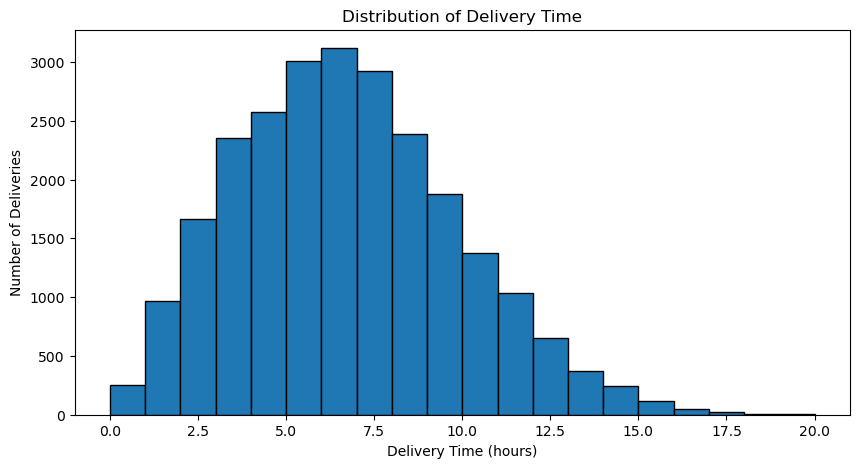

In [38]:
plt.figure(figsize=(10,5))

plt.hist(df["delivery_time_hours_clean"],
    bins= range(0,21),
    edgecolor= "black"
)

plt.xlabel("Delivery Time (hours)")
plt.ylabel("Number of Deliveries")
plt.title("Distribution of Delivery Time")

plt.show()

In [43]:
#**Validation:** Confirm that the engineered columns have been added to the DataFrame.
df.columns

Index(['delivery_id', 'delivery_partner', 'package_type', 'vehicle_type',
       'delivery_mode', 'region', 'weather_condition', 'distance_km',
       'package_weight_kg', 'delivery_time_hours', 'expected_time_hours',
       'delayed', 'delivery_status', 'delivery_rating', 'delivery_cost',
       'expected_time_hours_clean', 'delivery_time_hours_clean', 'delay_hours',
       'on_time_flag'],
      dtype='object')

### 6.3 Expected Delivery Time Analysis

In [40]:
df["expected_time_hours_clean"].value_counts().sort_index()

expected_time_hours_clean
2     1015
3     1029
4     1037
5     1080
6     1013
7     1051
8     6287
16    6302
24    6186
Name: count, dtype: int64

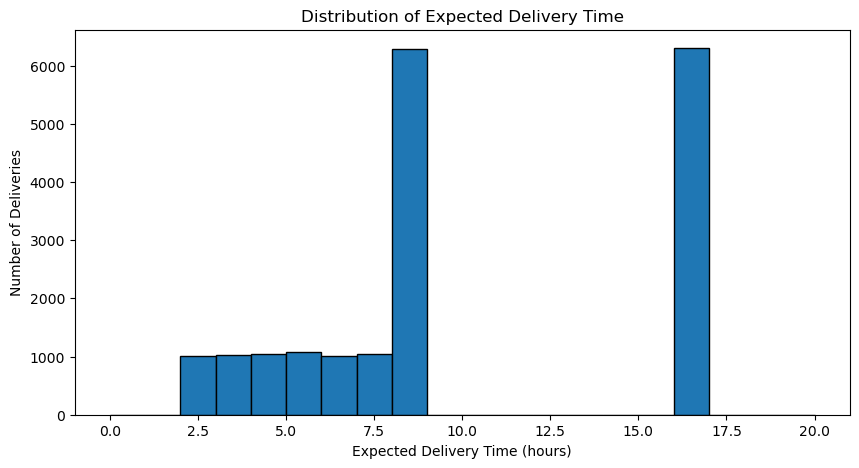

In [41]:
plt.figure(figsize=(10,5))

plt.hist(df["expected_time_hours_clean"],
    bins= range(0,21),
    edgecolor= "black"
)

plt.xlabel("Expected Delivery Time (hours)")
plt.ylabel("Number of Deliveries")
plt.title("Distribution of Expected Delivery Time")

plt.show()

### 6.4 Delay Analysis

In [25]:
df["delay_hours"].value_counts().sort_index()

delay_hours
-24      61
-23     224
-22     410
-21     585
-20     662
-19     729
-18     766
-17     733
-16     690
-15     693
-14     749
-13     841
-12     804
-11     832
-10     833
-9      812
-8      654
-7      739
-6      755
-5      853
-4      804
-3      906
-2     1153
-1     1552
 0     1694
 1     1506
 2     1163
 3      983
 4      765
 5      492
 6      302
 7      149
 8       72
 9       23
 10       7
 11       3
 12       1
Name: count, dtype: int64

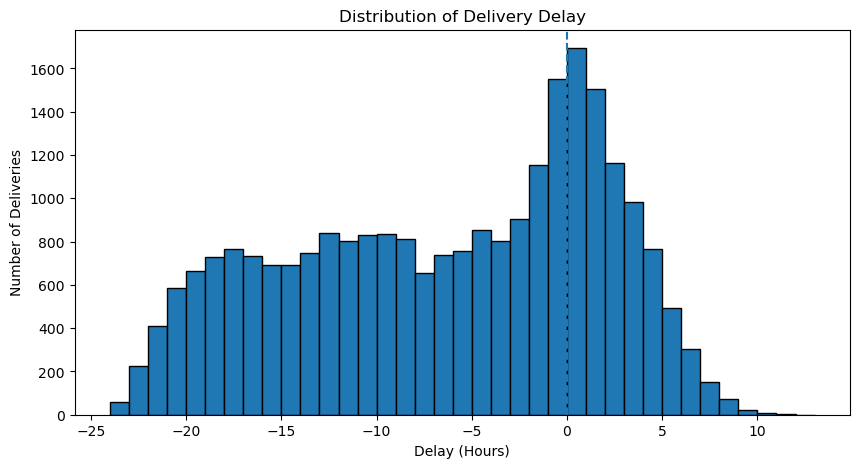

In [27]:
plt.figure(figsize=(10,5))
plt.hist(df["delay_hours"],
         bins= range(-24,14),
         edgecolor= "black"
        )
plt.axvline(0, linestyle="--")

plt.xlabel("Delay (Hours)")
plt.ylabel("Number of Deliveries")
plt.title("Distribution of Delivery Delay")

plt.show()

### 6.5 Delivery Cost Analysis

In [28]:
df["delivery_cost"].describe()

count    25000.000000
mean       864.944579
std        435.712593
min         95.667400
25%        490.800000
50%        867.535000
75%       1237.910000
max       1632.720600
Name: delivery_cost, dtype: float64

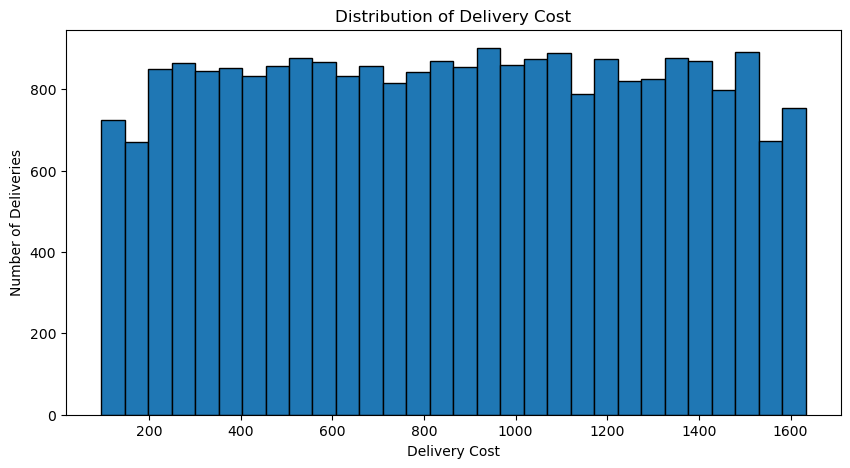

In [30]:
plt.figure(figsize=(10,5))

plt.hist(df["delivery_cost"],
         bins= 30,
    edgecolor= "black"
)

plt.xlabel("Delivery Cost")
plt.ylabel("Number of Deliveries")
plt.title("Distribution of Delivery Cost")

plt.show()

### 6.6 Delivery Distance Analysis

In [31]:
df["distance_km"].describe()

count    25000.000000
mean       150.390436
std         86.409745
min          3.600000
25%         75.900000
50%        151.000000
75%        224.900000
max        297.100000
Name: distance_km, dtype: float64

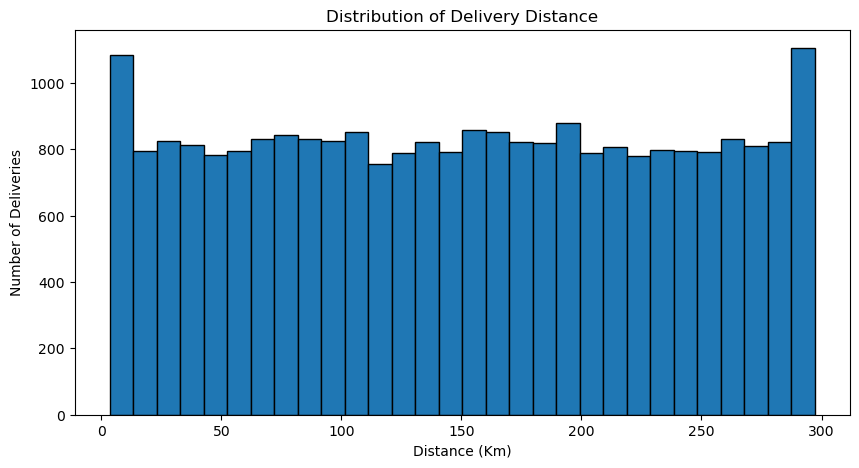

In [32]:
plt.figure(figsize=(10,5))

plt.hist(df["distance_km"],
         bins= 30,
    edgecolor= "black"
)

plt.xlabel("Distance (Km)")
plt.ylabel("Number of Deliveries")
plt.title("Distribution of Delivery Distance")

plt.show()

### 6.7 Package Weight Analysis

In [33]:
df["package_weight_kg"].describe()

count    25000.000000
mean        25.145898
std         14.368663
min          0.670000
25%         12.680000
50%         25.145000
75%         37.660000
max         49.520000
Name: package_weight_kg, dtype: float64

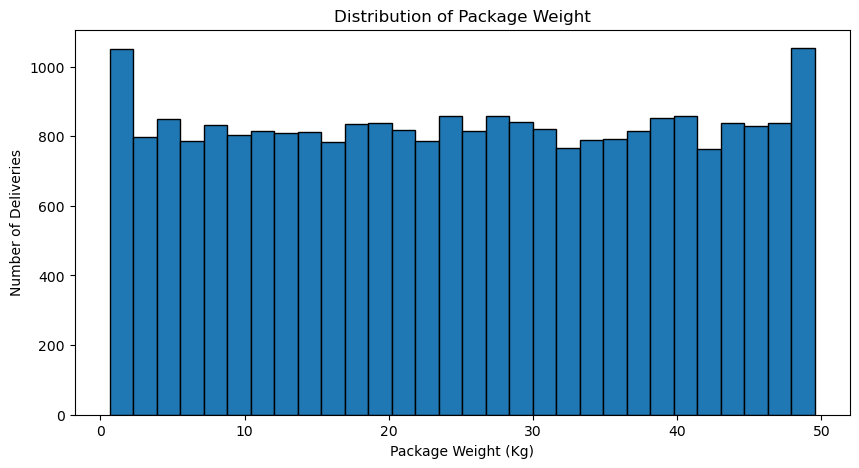

In [34]:
plt.figure(figsize=(10,5))

plt.hist(df["package_weight_kg"],
         bins= 30,
    edgecolor= "black"
)

plt.xlabel("Package Weight (Kg)")
plt.ylabel("Number of Deliveries")
plt.title("Distribution of Package Weight")

plt.show()

### 6.8 Distance vs Delivery Time

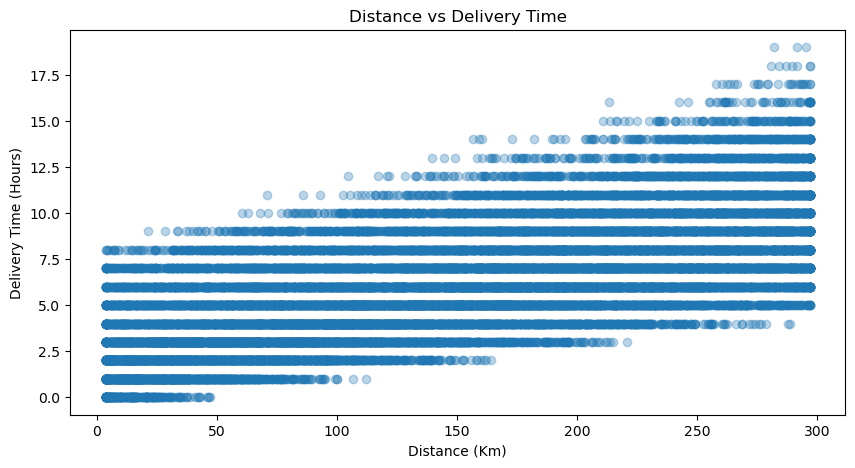

In [36]:
plt.figure(figsize=(10,5))

plt.scatter(
    df["distance_km"],
    df["delivery_time_hours_clean"],
    alpha= 0.3
)

plt.xlabel("Distance (Km)")
plt.ylabel("Delivery Time (Hours)")
plt.title("Distance vs Delivery Time")

plt.show()

In [37]:
df["distance_km"].corr(df["delivery_time_hours_clean"])

np.float64(0.6858833649122646)

### 6.9 Distance vs Delivery Cost

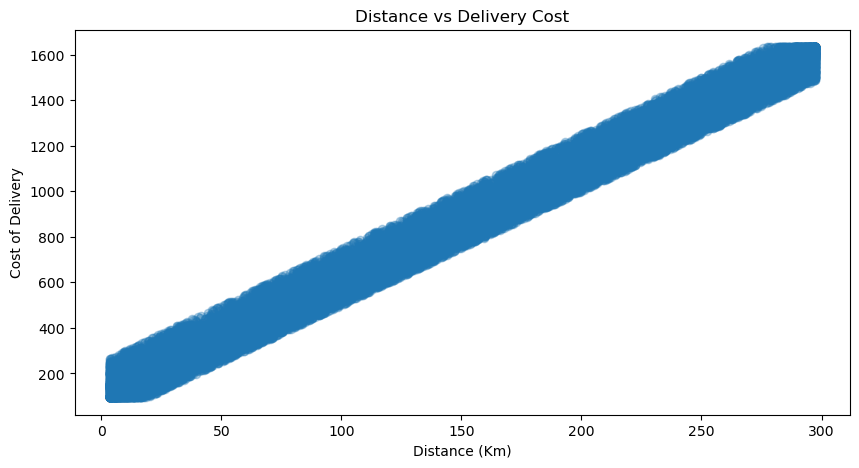

In [42]:
plt.figure(figsize=(10,5))

plt.scatter(
    df["distance_km"],
    df["delivery_cost"],
    alpha= 0.3
)

plt.xlabel("Distance (Km)")
plt.ylabel("Cost of Delivery")
plt.title("Distance vs Delivery Cost")

plt.show()

In [39]:
df["distance_km"].corr(df["delivery_cost"])

np.float64(0.9907716907515624)

### 6.10 Package Weight vs Delivery Cost

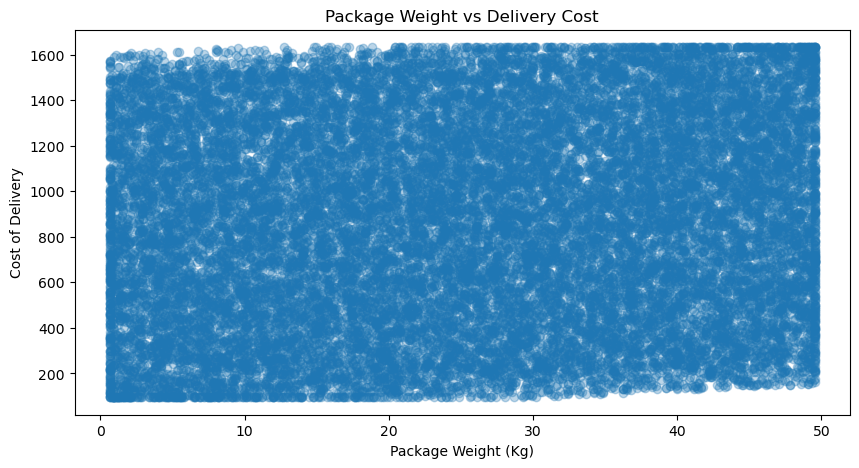

In [40]:
plt.figure(figsize=(10,5))

plt.scatter(
    df["package_weight_kg"],
    df["delivery_cost"],
    alpha= 0.3
)

plt.xlabel("Package Weight (Kg)")
plt.ylabel("Cost of Delivery")
plt.title("Package Weight vs Delivery Cost")

plt.show()

In [41]:
df["package_weight_kg"].corr(df["delivery_cost"])

np.float64(0.09947871252003071)

### 6.11 Delay Rate by Delivery Mode

In [42]:
df.groupby("delivery_mode")["delayed"].value_counts()

delivery_mode  delayed
express        yes        4599
               no         1634
same day       no         4236
               yes        2043
standard       no         6186
two day        no         6275
               yes          27
Name: count, dtype: int64

In [43]:
df.groupby("delivery_mode")["delayed"].apply(lambda x: (x== "yes").mean() * 100)

delivery_mode
express     73.784694
same day    32.537028
standard     0.000000
two day      0.428435
Name: delayed, dtype: float64

In [44]:
mode_delay= (df.groupby("delivery_mode")["delayed"].apply(lambda x: (x== "yes").mean() * 100).reset_index(name="delay_rate"))
mode_delay

,delivery_mode,delay_rate
0,express,73.784694
1,same day,32.537028
2,standard,0.000000
3,two day,0.428435


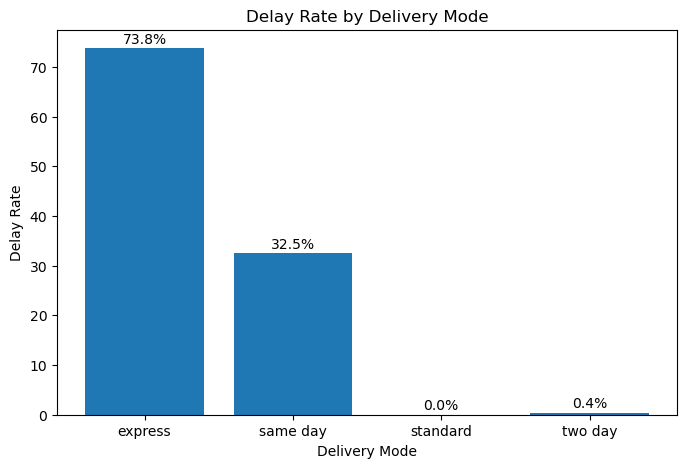

In [47]:
plt.figure(figsize=(8,5))

bars= plt.bar(
    mode_delay["delivery_mode"],
    mode_delay["delay_rate"]
)

plt.xlabel("Delivery Mode")
plt.ylabel("Delay Rate")
plt.title("Delay Rate by Delivery Mode")

for bar in bars:
    height= bar.get_height()
    plt.text(
         bar.get_x() + bar.get_width() / 2,
    height + 1,
    f"{height:.1f}%",
    ha="center"
)

plt.show()

### 6.12 Delay Rate by Weather Condition

In [49]:
weather_delay= (df.groupby("weather_condition")["delayed"].apply(lambda x:(x=="yes").mean() * 100).reset_index(name="delay_rate"))
weather_delay

,weather_condition,delay_rate
0,clear,17.434530
1,cold,16.017316
2,foggy,30.315241
3,hot,17.118644
4,rainy,37.353153
5,stormy,41.448309


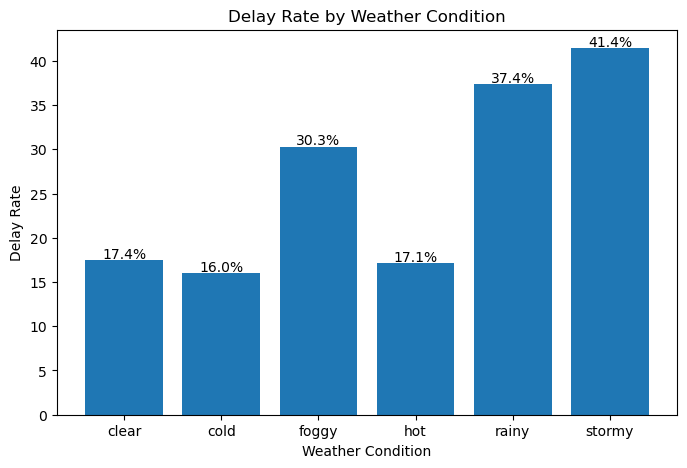

In [61]:
plt.figure(figsize=(8,5))

bars= plt.bar(
    weather_delay["weather_condition"],
    weather_delay["delay_rate"]
)

plt.xlabel("Weather Condition")
plt.ylabel("Delay Rate")
plt.title("Delay Rate by Weather Condition")

for bar in bars:
    height= bar.get_height()
    plt.text(
         bar.get_x() + bar.get_width() / 2,
    height + 0.2,
    f"{height:.1f}%",
    ha="center"
)

plt.show()

### 6.13 Delay Rate by Delivery Partner

In [52]:
partner_delay= (df.groupby("delivery_partner")["delayed"].apply(lambda x:(x=="yes").mean() * 100).reset_index(name="delay_rate"))
partner_delay

,delivery_partner,delay_rate
0,amazon logistics,27.222427
1,blue dart,26.947820
2,delhivery,24.802584
3,dhl,26.338330
4,ecom express,26.634827
5,ekart,27.418779
6,fedex,25.159688
7,shadowfax,27.302632
8,xpressbees,28.273178


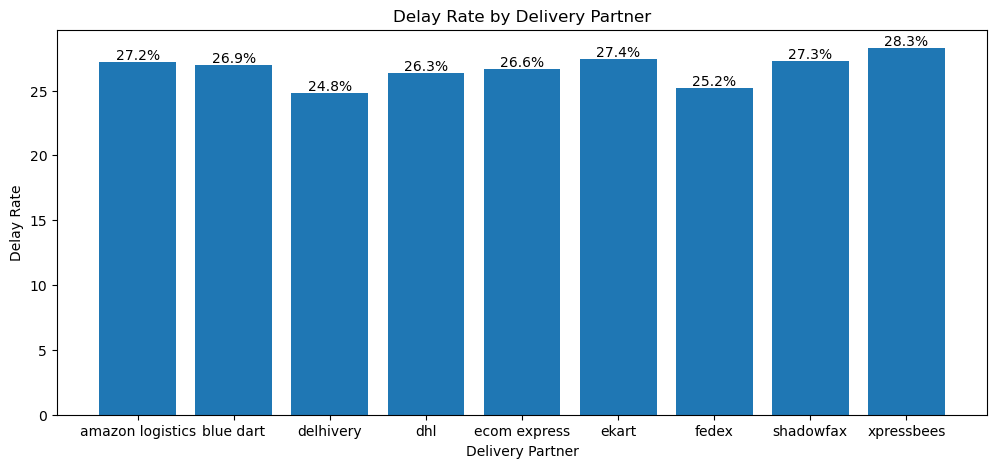

In [60]:
plt.figure(figsize=(12,5))

bars= plt.bar(
    partner_delay["delivery_partner"],
    partner_delay["delay_rate"]
)

plt.xlabel("Delivery Partner")
plt.ylabel("Delay Rate")
plt.title("Delay Rate by Delivery Partner")

for bar in bars:
    height= bar.get_height()
    plt.text(
         bar.get_x() + bar.get_width() / 2,
    height + 0.2,
    f"{height:.1f}%",
    ha="center"
)

plt.show()

### 6.14 Delay Rate by Region

In [56]:
region_delay= (df.groupby("region")["delayed"].apply(lambda x:(x=="yes").mean() * 100).reset_index(name="delay_rate"))
region_delay

,region,delay_rate
0,central,27.252964
1,east,25.797926
2,north,26.571024
3,south,26.783203
4,west,26.947988


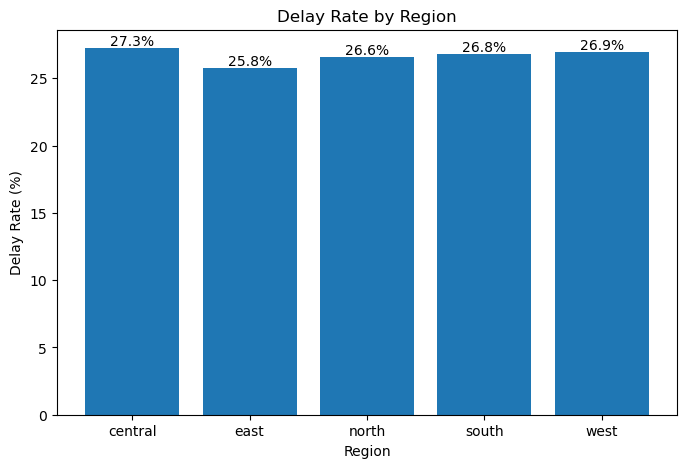

In [57]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    region_delay["region"],
    region_delay["delay_rate"]
)

plt.xlabel("Region")
plt.ylabel("Delay Rate (%)")
plt.title("Delay Rate by Region")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.2,
        f"{height:.1f}%",
        ha="center"
    )

plt.show()

### 6.15 Delay Rate by Vehicle Type

In [58]:
vehicle_delay= (df.groupby("vehicle_type")["delayed"].apply(lambda x:(x=="yes").mean() * 100).reset_index(name="delay_rate"))
vehicle_delay

,vehicle_type,delay_rate
0,bike,27.043269
1,ev bike,26.434329
2,ev van,26.627794
3,scooter,26.137997
4,truck,27.044632
5,van,26.773346


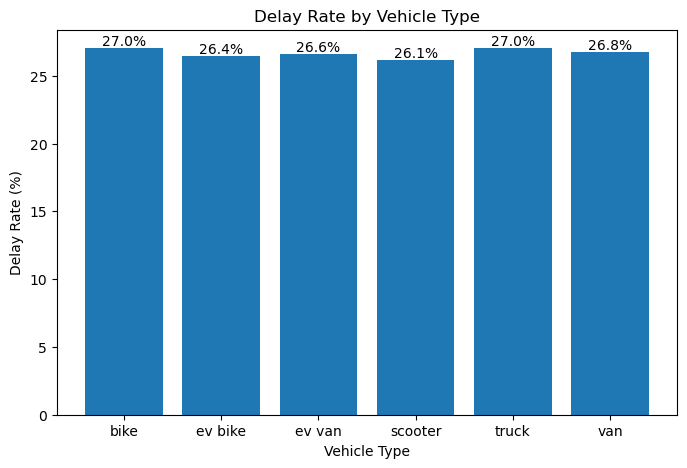

In [59]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    vehicle_delay["vehicle_type"],
    vehicle_delay["delay_rate"]
)

plt.xlabel("Vehicle Type")
plt.ylabel("Delay Rate (%)")
plt.title("Delay Rate by Vehicle Type")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.2,
        f"{height:.1f}%",
        ha="center"
    )

plt.show()

### 6.16 Delay Rate by Package Type

In [63]:
package_delay = (
    df.groupby("package_type")["delayed"]
      .apply(lambda x: (x == "yes").mean() * 100)
      .reset_index(name="delay_rate")
)
package_delay

,package_type,delay_rate
0,automobile parts,26.189624
1,clothing,26.093242
2,cosmetics,27.040816
3,documents,27.165775
4,electronics,27.184814
5,fragile items,26.650281
6,furniture,24.763292
7,groceries,27.441515
8,pharmacy,27.544484


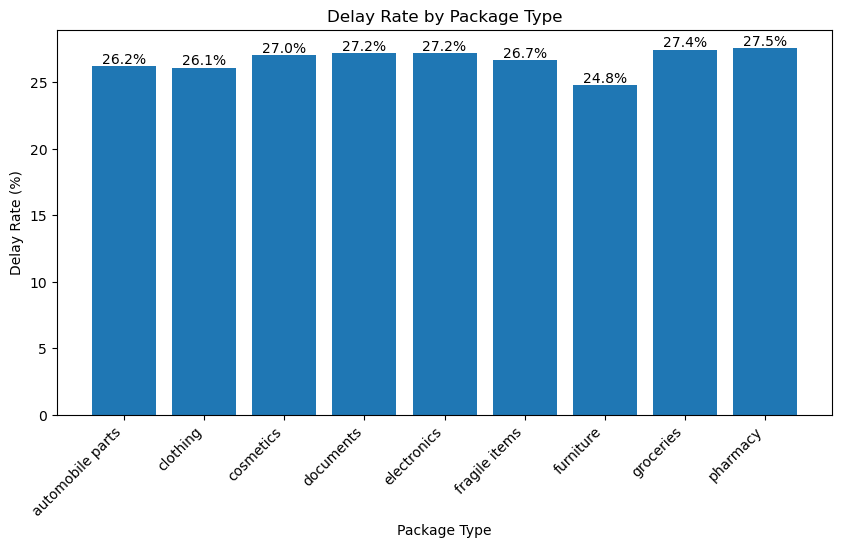

In [64]:
plt.figure(figsize=(10, 5))

bars = plt.bar(
    package_delay["package_type"],
    package_delay["delay_rate"]
)

plt.xlabel("Package Type")
plt.ylabel("Delay Rate (%)")
plt.title("Delay Rate by Package Type")

plt.xticks(rotation=45, ha="right")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.2,
        f"{height:.1f}%",
        ha="center"
    )

plt.show()

### 6.17 Delivery Status Analysis

In [65]:
df["delivery_status"].value_counts()

delivery_status
delivered    18331
delayed       5341
failed        1328
Name: count, dtype: int64

In [67]:
df["delivery_status"].value_counts(normalize=True) * 100

delivery_status
delivered    73.324
delayed      21.364
failed        5.312
Name: proportion, dtype: float64

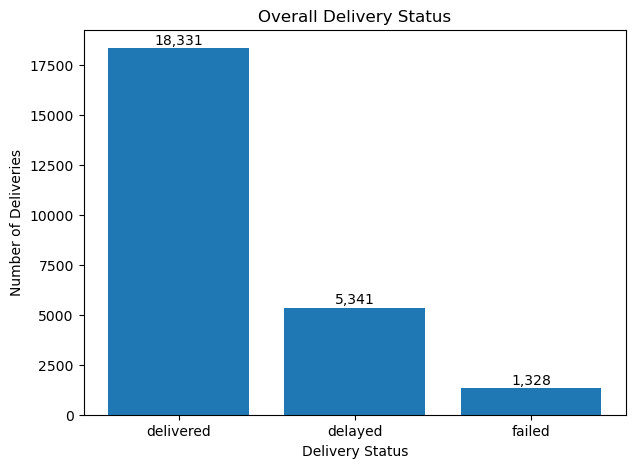

In [68]:
status_counts = df["delivery_status"].value_counts()

plt.figure(figsize=(7, 5))

bars = plt.bar(
    status_counts.index,
    status_counts.values
)

plt.xlabel("Delivery Status")
plt.ylabel("Number of Deliveries")
plt.title("Overall Delivery Status")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 200,
        f"{int(height):,}",
        ha="center"
    )

plt.show()

### 6.18 Failure Rate by Delivery Mode

In [71]:
mode_failure= (df.groupby("delivery_mode")["delivery_status"].apply(lambda x:(x== "failed").mean() * 100).reset_index(name="failure_rate"))
mode_failure

,delivery_mode,failure_rate
0,express,14.423231
1,same day,6.752668
2,standard,0.000000
3,two day,0.079340


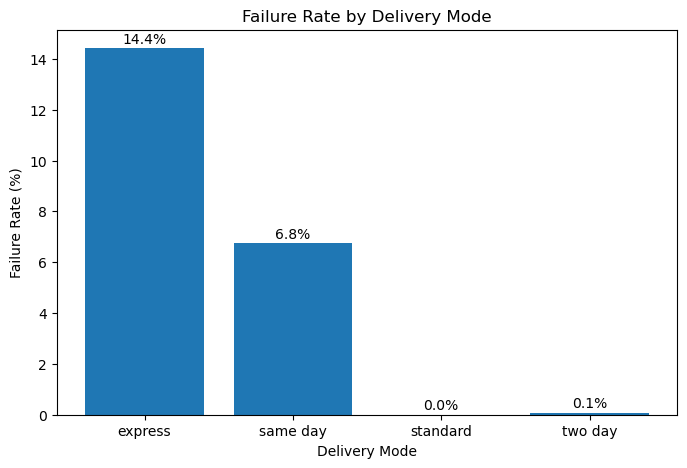

In [73]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    mode_failure["delivery_mode"],
    mode_failure["failure_rate"]
)

plt.xlabel("Delivery Mode")
plt.ylabel("Failure Rate (%)")
plt.title("Failure Rate by Delivery Mode")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.2,
        f"{height:.1f}%",
        ha="center"
    )

plt.show()

### 6.19 Failure Rate by Weather Condition

In [75]:
weather_failure= (df.groupby("weather_condition")["delivery_status"].apply(lambda x:(x=="failed").mean() * 100).reset_index(name="failure_rate"))
weather_failure

,weather_condition,failure_rate
0,clear,3.176528
1,cold,3.150553
2,foggy,5.925575
3,hot,3.244552
4,rainy,7.384320
5,stormy,8.909004


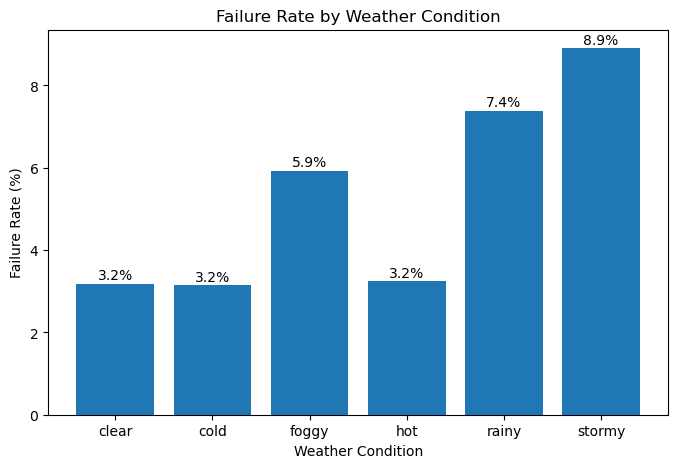

In [77]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    weather_failure["weather_condition"],
    weather_failure["failure_rate"]
)

plt.xlabel("Weather Condition")
plt.ylabel("Failure Rate (%)")
plt.title("Failure Rate by Weather Condition")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.1,
        f"{height:.1f}%",
        ha="center"
    )

plt.show()

### 6.20 Customer Rating Analysis

In [78]:
df["delivery_rating"].value_counts().sort_index()

delivery_rating
1     920
2    3602
3    5773
4    7318
5    7387
Name: count, dtype: int64

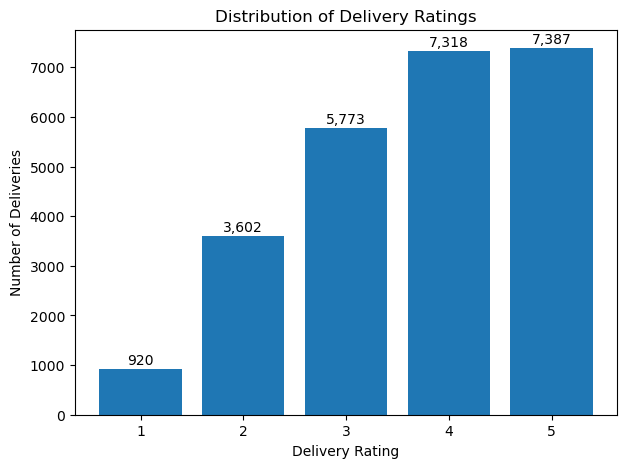

In [79]:
rating_counts = df["delivery_rating"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

bars = plt.bar(
    rating_counts.index,
    rating_counts.values
)

plt.xlabel("Delivery Rating")
plt.ylabel("Number of Deliveries")
plt.title("Distribution of Delivery Ratings")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 100,
        f"{int(height):,}",
        ha="center"
    )

plt.show()


### 6.21 Average Customer Rating by Delay Status

In [11]:
rating_delay= (df.groupby("delayed")["delivery_rating"].mean().reset_index())

rating_delay

,delayed,delivery_rating
0,no,4.205172
1,yes,2.183986


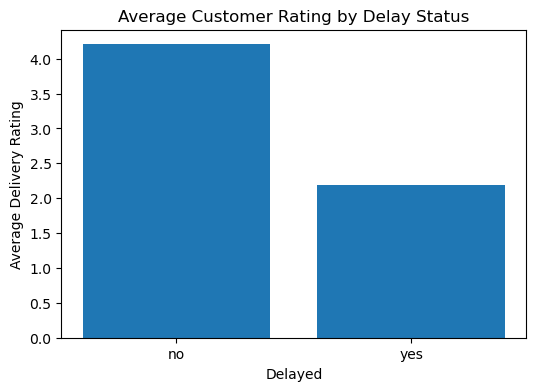

In [13]:
plt.figure(figsize=(6,4))

plt.bar(
    rating_delay["delayed"],
    rating_delay["delivery_rating"]
)

plt.xlabel("Delayed")
plt.ylabel("Average Delivery Rating")
plt.title("Average Customer Rating by Delay Status")

plt.show()

### 6.22 Average Customer Rating by Delivery Status

In [14]:
rating_status= (df.groupby("delivery_status")["delivery_rating"].mean().reset_index())

rating_status

,delivery_status,delivery_rating
0,delayed,2.401985
1,delivered,4.205172
2,failed,1.307229


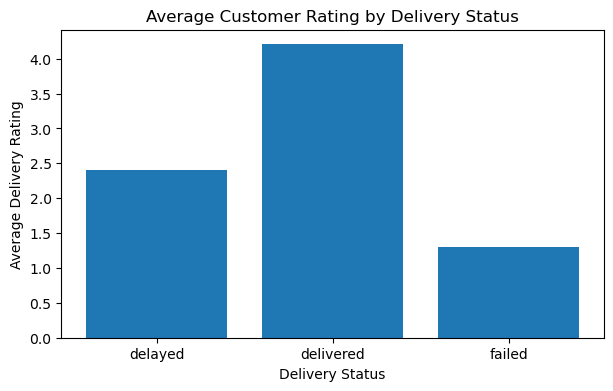

In [15]:
plt.figure(figsize=(7, 4))

plt.bar(
    rating_status["delivery_status"],
    rating_status["delivery_rating"]
)

plt.xlabel("Delivery Status")
plt.ylabel("Average Delivery Rating")
plt.title("Average Customer Rating by Delivery Status")

plt.show()

### 6.23 Correlation Analysis

In [17]:
numeric_cols= [
        "distance_km",
    "package_weight_kg",
    "delivery_time_hours_clean",
    "expected_time_hours_clean",
    "delay_hours",
    "delivery_rating",
    "delivery_cost"
]
    

In [18]:
correlation_matrix= df[numeric_cols].corr()

correlation_matrix

,distance_km,package_weight_kg,delivery_time_hours_clean,expected_time_hours_clean,delay_hours,delivery_rating,delivery_cost
distance_km,1.000000,0.002311,0.685883,0.045236,0.224596,-0.132634,0.990772
package_weight_kg,0.002311,1.000000,0.001242,0.001442,-0.000867,-0.002891,0.099479
delivery_time_hours_clean,0.685883,0.001242,1.000000,0.039755,0.351996,-0.272637,0.678911
expected_time_hours_clean,0.045236,0.001442,0.039755,1.000000,-0.921268,0.462872,-0.025480
delay_hours,0.224596,-0.000867,0.351996,-0.921268,1.000000,-0.539712,0.288125
delivery_rating,-0.132634,-0.002891,-0.272637,0.462872,-0.539712,1.000000,-0.160679
delivery_cost,0.990772,0.099479,0.678911,-0.025480,0.288125,-0.160679,1.000000


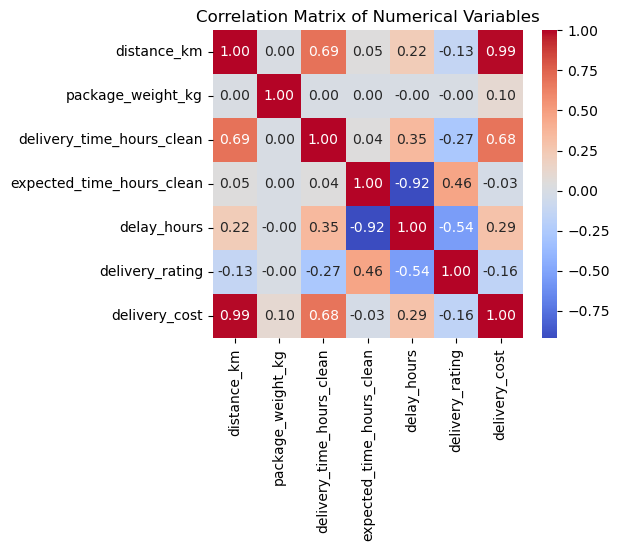

In [21]:
plt.figure(figsize=(5,4))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix of Numerical Variables")
plt.show()

## 7. Key Findings

### Operational Performance

- 73.32% of deliveries were recorded as delivered, while 21.36% were delayed and 5.31% failed.
- Delivery mode showed substantial variation in recorded delay rates, with Express at 73.78%, Same Day at 32.54%, Two Day at 0.43%, and Standard at 0%.
- Weather conditions were associated with different recorded delay rates, ranging from 16.02% under cold conditions to 41.45% under stormy conditions.

### Cost and Operational Relationships

- Distance and delivery cost showed a very strong positive correlation of 0.99.
- Distance and actual delivery time showed a moderately strong positive correlation of 0.69.
- Package weight and delivery cost showed a weak positive correlation of 0.10.

### Customer Experience

- Deliveries recorded as not delayed had an average rating of 4.21, compared with 2.18 for deliveries recorded as delayed.
- Average ratings varied by delivery status: 4.21 for delivered, 2.40 for delayed, and 1.31 for failed deliveries.
- Delay hours and customer rating showed a moderate negative correlation of -0.54.

### Data Quality Observations

- 255 records contained an actual delivery time of 0 hours. These records were retained but identified as a data-quality anomaly.
- The source `delayed` field and the calculated `on_time_flag` do not completely agree. The source field also corresponds to failed deliveries, so both definitions were retained separately.

## 8. Conclusion

The analysis shows that delivery performance varies considerably across delivery modes and weather conditions, with Express and Same Day deliveries recording higher delay rates than Standard and Two Day deliveries. Weather conditions such as stormy and rainy conditions were also associated with higher recorded delay rates.

Delivery distance showed a very strong relationship with delivery cost and a moderately strong relationship with actual delivery time, while package weight had only a weak relationship with delivery cost.

Customer experience was closely associated with delivery outcomes. Deliveries recorded as delayed or failed had substantially lower average customer ratings than delivered orders.

The analysis also identified data-quality considerations, including 255 records with an actual delivery time of 0 hours and differences between the source `delayed` field and the calculated timing-based `on_time_flag`. These issues were documented and the original records were retained for further analysis.

Overall, the findings provide a foundation for identifying operational areas that may require closer monitoring and for developing an interactive Power BI dashboard for business decision-making.